In [79]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import os
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

### Now We Load The Dataset

In [80]:
df = pd.read_csv("../dataset/data.csv", sep=";")
df.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance	                     4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

The datasets are loaded perfectly.

# Encoding Target & Features

Because machine learning models cannot understand text directly, we will use Label Encoding to convert our target column into numeric values (0, 1, and 2). Then, we will use One-Hot Encoding to convert the remaining categorical features into dummy variables.

In [82]:
le = LabelEncoder()
df["Target"] = le.fit_transform(df["Target"])

print("Class mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
print(df["Target"].value_counts())

df = pd.get_dummies(df, drop_first=True)

Class mapping: {'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}
Target
2    2209
0    1421
1     794
Name: count, dtype: int64


We can see that the text-based categories have been successfully converted into numbers. There are 3 classes in total, so our KNN model will perform multiclass classification. Finally, the remaining text features are transformed into numerical dummy variables so the model can easily process them.

# Separating features and target

In [83]:
X = df.drop("Target", axis=1)
y = df["Target"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (4424, 36)
Target shape: (4424,)


We can see that our dataset is successfully separated into 4,424 input features and target labels.

# Spliting the dataset

In [84]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (3539, 36)
Testing data: (885, 36)


To prepare for machine learning, this data is divided into two parts, using 80% of the data (3,539 students) to train the model and saving the remaining 20% (885 students) to accurately test its performance.

# Feature Scaling

K-Nearest Neighbors (KNN) is a distance-based algorithm. If features are on different scales, the model will be biased towards features with larger values. Therefore, we must standardize our input features using `StandardScaler` before training.

In [85]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Features scaled successfully.")

Features scaled successfully.


# Starting Training the Baseline Model (KNN)

We will now initialize the K-Nearest Neighbors classifier and train the model using our scaled training data.

In [86]:
knn_model = KNeighborsClassifier(n_neighbors=5)

knn_model.fit(X_train_scaled, y_train)

print("KNN model trained successfully.")

KNN model trained successfully.


# Prediction Generating

In [87]:
y_pred = knn_model.predict(X_test_scaled)
print("Predictions generated successfully.")

Predictions generated successfully.


# Calculate Accuracy

In [88]:
accuracy = accuracy_score(y_test, y_pred)

print(f"KNN Accuracy: {accuracy:.4f}")
print(f"KNN Accuracy: {accuracy * 100:.2f}%")

KNN Accuracy: 0.6678
KNN Accuracy: 66.78%


We can see the overall accuracy of the KNN classifier on the test dataset.

# Classification Report

In [89]:
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=le.classes_))

Classification Report:
              precision    recall  f1-score   support

     Dropout       0.73      0.68      0.70       284
    Enrolled       0.28      0.21      0.24       159
    Graduate       0.73      0.83      0.77       442

    accuracy                           0.67       885
   macro avg       0.58      0.57      0.57       885
weighted avg       0.65      0.67      0.66       885



# Confusion Matrix

In [90]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[192  33  59]
 [ 47  34  78]
 [ 24  53 365]]


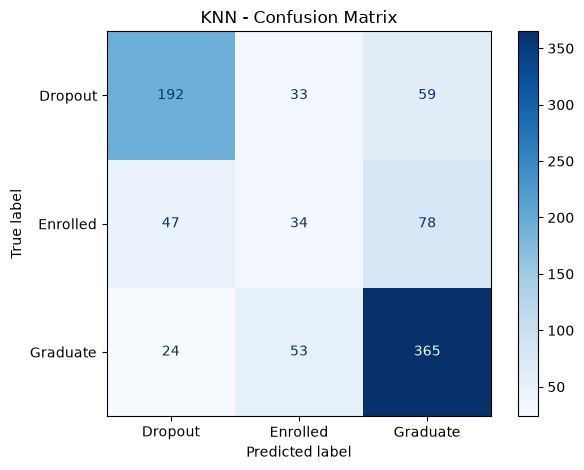

In [91]:
os.makedirs("../results/knn", exist_ok=True)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=le.classes_
)

disp.plot(cmap="Blues")

plt.title("KNN - Confusion Matrix")
plt.tight_layout()

plt.savefig(
    "../results/knn/confusion_matrix_knn.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Confusion Matrix Observation

We can see from the confusion matrix how the KNN model performs across all three student outcomes. While it correctly identifies a significant portion of **Graduate** and **Dropout** students, the distance-based nature of the algorithm often struggles with the overlapping feature space of the **Enrolled** class, leading to misclassifications between Enrolled and the other two categories.

*(Note: Unlike tree-based models such as Decision Trees or Random Forests, KNN is a distance-based algorithm and does not provide an inherent `feature_importances_` attribute. Therefore, direct feature importance plotting is omitted for this model.)*

### Observation & Model Summary

In this notebook, we implemented a **K-Nearest Neighbors (KNN)** classifier to predict multiclass student outcomes (**Dropout**, **Enrolled**, and **Graduate**). After standardizing the input features—a mandatory step for distance-based algorithms—and evaluating the model on the test dataset (885 records), it achieved an overall **Accuracy of 66.78%**[cite: 13].

Analyzing the class-specific performance, the model showed moderate capability in identifying **Graduate** students, achieving a **Precision of 0.73**, **Recall of 0.83**, and an **F1-score of 0.77**[cite: 13]. For the **Dropout** class, the model secured a **Precision of 0.73**, **Recall of 0.68**, and an **F1-score of 0.70**[cite: 13]. However, predicting the **Enrolled** class proved to be highly problematic, yielding a very poor **Precision of 0.28**, **Recall of 0.21**, and an **F1-score of 0.24**[cite: 13]. 

This significant drop in performance is largely due to KNN's reliance on Euclidean distance in a high-dimensional space; the overlapping academic and financial profiles of 'Enrolled' students make them extremely difficult to isolate cleanly from actual dropouts and graduates[cite: 13]. Furthermore, unlike tree-based models, KNN does not provide an inherent feature importance metric[cite: 13]. Overall, this performance highlights the limitations of traditional distance-based baseline models on complex, imbalanced datasets and strongly justifies our shift towards advanced deep learning architectures like LSTM combined with SHAP evaluations.